**Autores:** Jesús Moreno Cruz y Corro

# Regresión lineal para predicción de progresión de diabetes
- age: Representa la edad del paciente, normalizada (no es la edad real, sino una representación estandarizada).
- sex: Sexo del paciente, representado como una variable numérica normalizada (valores entre -0.5 y 0.5).
- bmi: Índice de Masa Corporal (Body Mass Index, BMI), una medida del peso relativo al cuadrado de la altura.
- bp:
Promedio de presión arterial (Blood Pressure, BP), normalizada.
- s1: Nivel sérico de lípidos totales (colesterol total).
- s2: Nivel sérico de lipoproteínas de baja densidad (LDL, “colesterol malo”).
- s3: Nivel sérico de lipoproteínas de alta densidad (HDL, “colesterol bueno”).
- s4: Relación entre el colesterol total y HDL.
- s5: Nivel sérico de triglicéridos, representado como una medida numérica normalizada.
- s6: Nivel sérico de glucosa en ayuno, una medida clave en el monitoreo de la diabetes.

In [1]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

# Cargar el conjunto de datos
diabetes_data = load_diabetes()

# Convertir el conjunto de datos a un DataFrame para facilitar su manipulación
df = pd.DataFrame(data=diabetes_data.data, columns=diabetes_data.feature_names)
df['target'] = diabetes_data.target  # Agregar la variable objetivo al DataFrame

# Mostrar las primeras filas del DataFrame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 1. Exploración de los datos
Revisamos dimensiones, valores faltantes, estadísticas básicas y la relación de cada variable con la progresión de la diabetes.

In [2]:
# Dimensiones, valores faltantes y estadísticas básicas
print('Dimensiones:', df.shape)
print('Valores faltantes en total:', df.isnull().sum().sum())
df.describe().round(3)

Dimensiones: (442, 11)
Valores faltantes en total: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


In [3]:
# Correlación de cada característica con la variable objetivo
correlaciones = df.corr()['target'].drop('target').sort_values(ascending=False)
print(correlaciones.round(3))

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: target, dtype: float64


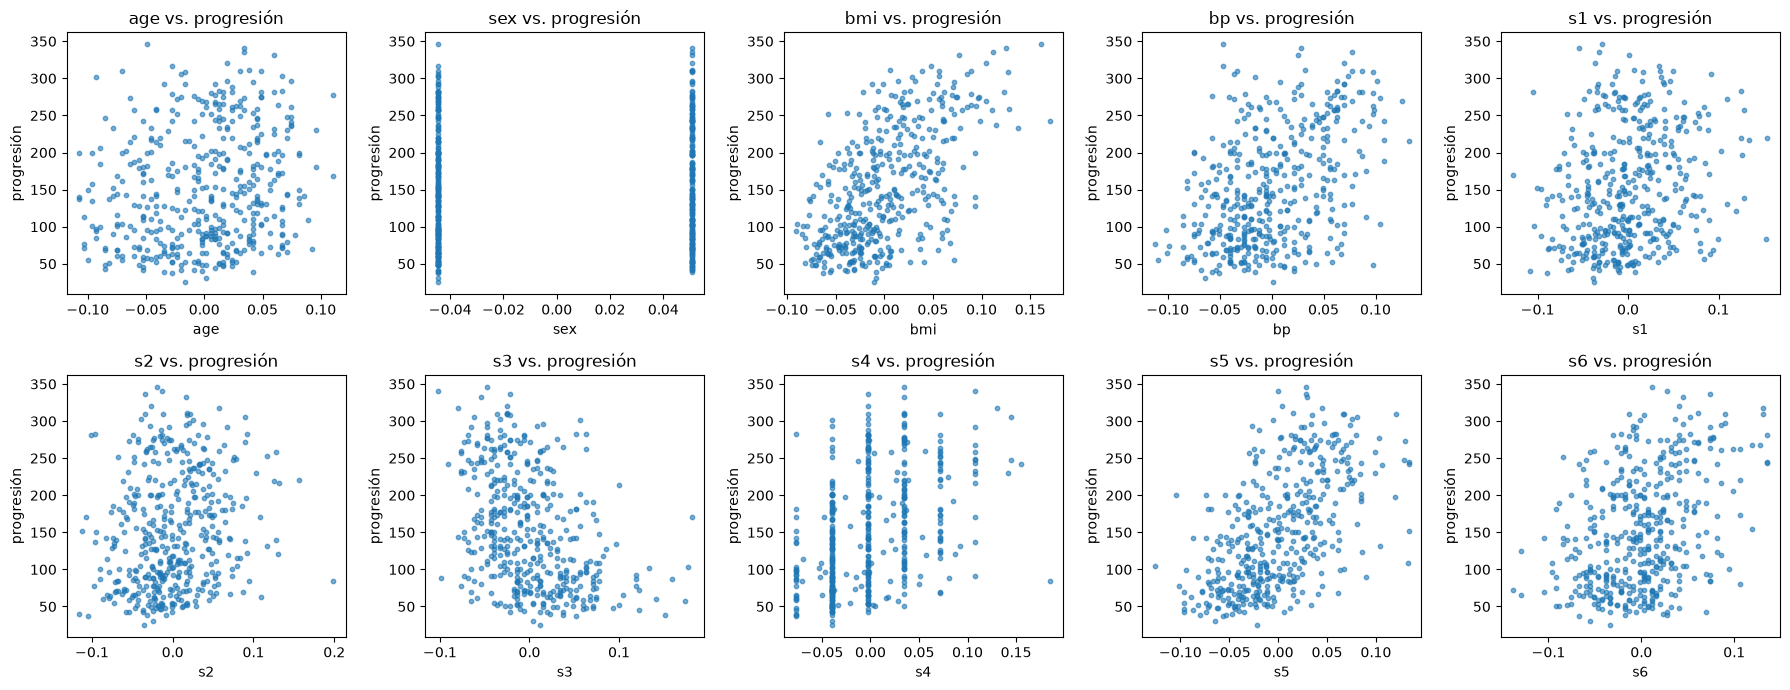

In [4]:
# Relación de cada característica con la progresión
fig, ejes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(ejes.flat, diabetes_data.feature_names):
    ax.scatter(df[col], df['target'], s=10, alpha=0.6)
    ax.set_title(f'{col} vs. progresión')
    ax.set_xlabel(col)
    ax.set_ylabel('progresión')
plt.tight_layout()
plt.show()

## 2. Preprocesamiento
Separamos los datos en entrenamiento (80 %) y prueba (20 %). El escalador se ajusta **solo con los datos de entrenamiento** para evitar fuga de información hacia el conjunto de prueba.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[diabetes_data.feature_names]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print('Entrenamiento:', X_train_s.shape, '| Prueba:', X_test_s.shape)

Entrenamiento: (353, 10) | Prueba: (89, 10)


## 3. Entrenamiento del modelo de regresión lineal

In [6]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X_train_s, y_train)

print('Intercepto:', round(modelo.intercept_, 3))
coeficientes = pd.Series(modelo.coef_, index=diabetes_data.feature_names)
coeficientes.sort_values(key=abs, ascending=False).round(3)

Intercepto: 153.737


s1    -44.449
s5     35.161
bmi    25.607
s2     24.641
bp     16.829
s4     13.139
sex   -11.512
s3      7.677
s6      2.351
age     1.754
dtype: float64

## 4. Evaluación
Usamos RMSE (error medio en las mismas unidades que la progresión) y \(R^2\) (proporción de la variabilidad explicada). Comparamos contra un modelo base que siempre predice la media del entrenamiento.

In [7]:
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

def evaluar(nombre, y_real, y_pred):
    return {
        'conjunto': nombre,
        'RMSE': round(np.sqrt(mean_squared_error(y_real, y_pred)), 3),
        'R2': round(r2_score(y_real, y_pred), 3),
    }

pred_train = modelo.predict(X_train_s)
pred_test = modelo.predict(X_test_s)
resultados = pd.DataFrame([
    evaluar('entrenamiento', y_train, pred_train),
    evaluar('prueba', y_test, pred_test),
])
print(resultados.to_string(index=False))

base = DummyRegressor(strategy='mean').fit(X_train_s, y_train)
print()
print(pd.DataFrame([evaluar('base (media), prueba', y_test, base.predict(X_test_s))]).to_string(index=False))

     conjunto   RMSE    R2
entrenamiento 53.559 0.528
       prueba 53.853 0.453

            conjunto   RMSE     R2
base (media), prueba 73.222 -0.012


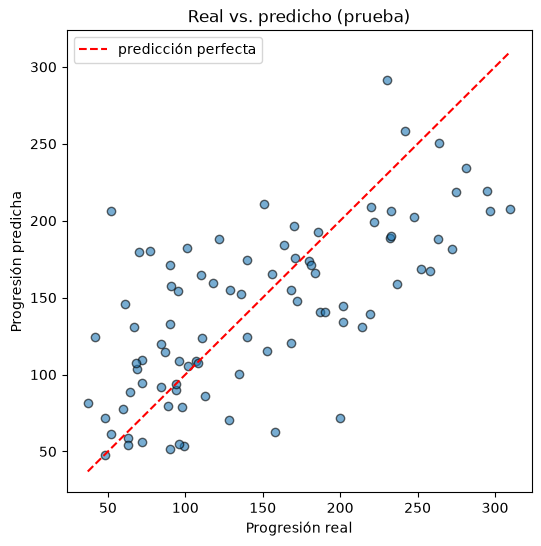

In [8]:
# Valores reales vs. predichos en el conjunto de prueba
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, alpha=0.6, edgecolor='k')
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
plt.plot(lims, lims, 'r--', label='predicción perfecta')
plt.xlabel('Progresión real')
plt.ylabel('Progresión predicha')
plt.title('Real vs. predicho (prueba)')
plt.legend()
plt.show()

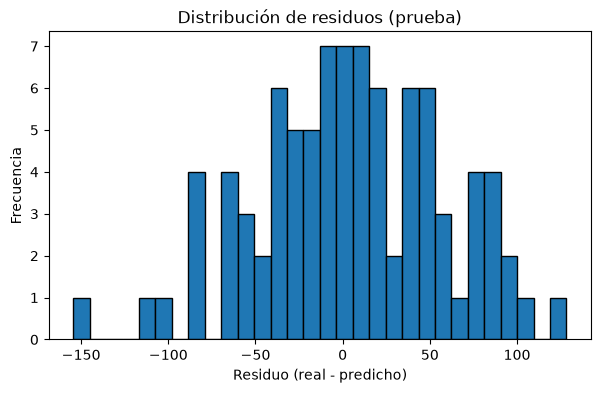

In [9]:
# Distribución de los residuos en el conjunto de prueba
residuos = y_test - pred_test
plt.figure(figsize=(7, 4))
plt.hist(residuos, bins=30, edgecolor='black')
plt.xlabel('Residuo (real - predicho)')
plt.ylabel('Frecuencia')
plt.title('Distribución de residuos (prueba)')
plt.show()

## 5. Conclusiones

- **Desempeño:** en el conjunto de prueba el modelo obtiene un RMSE de 53.9 y un \(R^2\) de 0.453. El modelo base que predice siempre la media tiene un RMSE de 73.2 y un \(R^2\) de -0.012, así que la regresión lineal sí aporta información. Como el \(R^2\) de entrenamiento (0.528) es parecido al de prueba, no hay sobreajuste importante.
- **Limitación:** el modelo explica cerca del 45 % de la variabilidad de la progresión. El resto puede deberse a relaciones no lineales o a factores que no están en el conjunto de datos.
- **Factores más influyentes:** según los coeficientes (cambio en la progresión por cada desviación estándar de la variable, con las demás fijas), destacan `s5` (triglicéridos, +35.2), `bmi` (+25.6), `s2` (LDL, +24.6) y `bp` (presión arterial, +16.8). Es consistente con las correlaciones de la sección 1, donde `bmi`, `s5` y `bp` son los predictores más fuertes.
- **Advertencia sobre `s1` y `s2`:** `s1` tiene un coeficiente de -44.4 y `s2` de +24.6, con signos opuestos. Ambas variables están muy correlacionadas entre sí (0.897), por lo que sus coeficientes individuales son inestables. Su efecto conjunto es más confiable que la interpretación de cada una por separado.
- **Mejoras posibles:** regularización (Ridge o Lasso) para manejar la multicolinealidad, y modelos no lineales si se busca mejorar el \(R^2\).